# Faster R-CNN and YOLO11s: class-wise WBF ensemble (pipeline, tuned)

## Overview

Parent run: `faster-rcnn-small-anchors` (T1, run `draklowell/faster-rcnn-small-anchors`): torchvision `fasterrcnn_resnet50_fpn_v2`, COCO weights, 1280 px, anchor sizes 16–256, 12 epochs. This notebook trains nothing. It reads the saved predictions of five finished runs (kernel sources) and fuses them.

**What changes.** One thing: the final detections are the class-wise weighted boxes fusion (WBF, Solovyev et al., arXiv:1910.13302) of the saved detections of five current-protocol runs, instead of the detections of one run. The five members (the `SOURCE_KERNELS` of the Config) are:

| Label | Run | Family | mAP@500 | AP_small | Public LB |
|---|---|---|---|---|---|
| T1 | `draklowell/faster-rcnn-small-anchors` | two_stage | 0.2312 | 0.1212 | 0.24489 |
| T2 | `dmnk1304/faster-rcnn-rpn-proposals` | two_stage | 0.2290 | 0.1194 | 0.2332 |
| T3 | `dmnk1304/faster-rcnn-giou` | two_stage | 0.2371 | 0.1312 | 0.22569 |
| P3 | `draklowell/pipeline-class-balance` | two_stage (pipeline) | 0.2247 | 0.1163 | 0.25857 |
| T7 | `dmnk1304/yolo11s-1280-p2` | anchor_free | 0.2165 | 0.1146 | not recorded |

Metrics: full val, `EXPERIMENTS.md`. The values of the members are not an input of this notebook. Each member's `result.json` is read at run time, and its recorded `mAP` is compared with a fresh COCOeval of its `val_predictions.json`.

| Item | Single run | This run |
|---|---|---|
| Detections | one run | WBF of five runs, class-wise |
| WBF IoU threshold | not applicable | chosen on quick-val frames from `WBF_IOU_THRESHOLD_GRID` |
| WBF `skip_box_thr` | not applicable | chosen on quick-val frames from `WBF_SKIP_BOX_THRESHOLD_GRID` |
| Member weights | not applicable | start at 1.0, each member tried at the values of `WBF_WEIGHT_GRID` on quick-val frames |
| Model weights | trained here | none trained; the members' predictions are read |

Config constants of the change: `SOURCE_KERNELS`, `WBF_IOU_THRESHOLD_GRID`, `WBF_SKIP_BOX_THRESHOLD_GRID`, `WBF_WEIGHT_GRID`. There is no forced side change. `PARENT_RUN` names T1 because it is the reference run of the Faster R-CNN members; the other four members are listed in `result.json` under `source_kernels`.

**Why** (`SCOPE.md` findings F21, F35, F44, F49, F51, F53, numbers in `EXPERIMENTS.md`):
- One seed per configuration gives a large run-to-run spread. Between T1 and T2 (one config change), the per-clip AP moves from −0.0460 to +0.0508 and the public LB by −0.0117. The full-val and LB order of the four 16–256-anchor Faster R-CNN runs is reversed (LB: P3 0.25857 > T1 0.24489 > T2 0.2332 > T3 0.22569; full-val mAP: T3 0.2371 > T1 0.2312 > T2 0.2290 > P3 0.2247). No single run is a safe pick, and fusing several runs is the planned variance reduction (`SCOPE.md` §3, principle 12).
- T7 (YOLO11s, P2 head) is 0.0147 mAP behind T1 on full val, but 0.0077 on the six clips without the 4K clip `uav0000268_05773_v`, and its per-class profile differs: bus AP 0.0802 against 0.0311 for T1, van 0.1482 against 0.2133. Its inference is 45 ms/image against 179–251 ms/image for the Faster R-CNN runs. It is an ensemble member, not a competitor.
- Bus has the lowest AP in every run that records it (0.03 in the four Faster R-CNN runs, 0.08 in T7). Whether this is limited by recall or by confusion with car is not measured for Faster R-CNN (T7: 0.68 of true bus boxes are predicted as car).

**Expectation.** If the members make different errors, the fused detections can score higher than the best member; the four Faster R-CNN members share backbone, weights, resolution and schedule, so their errors may be correlated, and T7 is the only member of another family. The size of the effect is not predicted. The decision rule of `SCOPE.md` §3.10 applies against T1: full-val mAP@500 at least 0.01 above T1 and a per-clip AP delta of the same sign on at least 5 of the 7 val clips.

**Tuning and validity.**
- The WBF settings are tuned on the 571 quick-val frames only (every 5th `val/` frame). Metrics are reported on all 2,846 val frames. The quick-val frames are a fifth of the full val, and the checkpoints of the members were also selected on them, so the full-val score is slightly optimistic.
- Nothing is fitted on training data, and no weights are learned. The tuned values are three scalars and five member weights. The settings are never tuned on the full val or on test.
- The members were trained on `train/` clips only, so the fused val score is a hold-out score.
- Test detections are the fusion of the members' `submission.csv` files (top 500 per image, scores rounded to 4 decimals), with the settings chosen on quick-val.

**Comparison with the legacy parent.** The parent T1 and the members T2, T3 and P3 ran under the current protocol, so no protocol difference enters the comparison of the ensemble with them. T7's own parent is the legacy run `dmnk1304/yolo-3-1280`; the legacy protocol differs from the current one as follows (from the † note in `EXPERIMENTS.md`): no ignore fill (ignored areas trained as background); GT inside ignore regions not dropped; checkpoint chosen by Ultralytics fitness on all val frames, no quick-val COCOeval; no `seed_everything`, no `MAX_TRAIN_HOURS` guard; pycocotools installed with pip; result file without versions, speed protocol and other core keys; legacy output names, `last.pt` and `runs/` saved; no `submission_check.json`; submission coordinates rounded to 1 decimal. This notebook compares the ensemble only with current-protocol runs; the delta of T7 against `yolo-3-1280` is not used.

**Extra outputs of this run.** Besides the standard outputs, `per_clip_ap.csv` and `size_breakdown.csv`:
- `history.csv`: the tuning trace (one row per evaluated setting, with quick-val mAP and AP50); there are no training epochs;
- `ensemble_ablation.csv`: each member alone, each pair, the four Faster R-CNN members, all five with equal weights and all five with tuned weights; full-val metrics, AP of bus and AP per clip;
- `val_noise.csv`: per run (five members and the ensemble) the AP per clip, the unweighted mean over the 7 clips, the same mean without the 4K clip, and the difference to T1 with a leave-one-clip-out range and a clip-level bootstrap interval;
- `bus_diagnostic.csv`: per run, the bus GT count, class-agnostic recall and recall with the correct class at IoU 0.5, and the class of the top-scoring detection that covers each matched bus box;
- `fig_tuning_quick_val.png` and `fig_ensemble_ablation.png` (+ `.csv`).

`best.pt` and the training curves do not apply, because nothing is trained.

**Protocol**

- Train: every 5th frame (`FRAME_STEP`) of each of the 56 `train/` clips, 4,868 frames. The split is by clip; no `val/` clip is used for training.
- Validation: all 2,846 frames of the 7 `val/` clips. Quick validation after every epoch: every 5th `val/` frame (`QUICK_VAL_STEP`), 571 frames.
- Ignore regions: in training frames, every ignore box is filled with the frame's own per-channel mean before augmentation, and GT boxes fully inside an ignore box are dropped. Val and test frames are not filled; evaluation treats ignore regions as `iscrowd=1`.
- Metric: pycocotools `COCOeval` on `val/annotations_coco.json` with `maxDets = [1, 100, 500]`; headline `mAP` is AP@[.50:.95] at 500 detections per frame. Inference in fp32 with score threshold 0.001 and at most 500 detections per frame.
- Checkpoint selection: the epoch with the best quick-val mAP. Quick val is a subset of val, so the final val score is slightly optimistic.
- Budget: `EPOCHS` planned epochs (Ultralytics 30, torchvision 12) and a `MAX_TRAIN_HOURS = 6` wall-clock guard, single Tesla T4.
- Reproducibility: `SEED = 42` and deterministic settings. Runs are reproducible in setup but not guaranteed bit-exact.

**How the protocol applies to a fusion run.**
- The split, the 56 training clips and the ignore handling belong to the members' training. This notebook only checks the frame counts. It does not fill ignore regions, because it trains nothing. Evaluation uses the same `val/annotations_coco.json` with `iscrowd=1`.
- There are no epochs. The "checkpoint" is the WBF setting with the best quick-val mAP@500, and `MAX_TRAIN_HOURS` bounds the tuning search. The members' detections come from fp32 inference with score threshold 0.001 and at most 500 detections per frame; the fused output is capped at 500 detections per frame as well.
- Speed: the fusion runs on the CPU. `ms_per_image` in `result.json` is the sum of the members' recorded `ms_per_image` plus the fusion time per frame (see `speed_protocol`).

**How weighted boxes fusion works**

Non-maximum suppression keeps one box of a group of overlapping boxes and drops the rest. WBF (Solovyev, Wang, Gabruseva, arXiv:1910.13302) uses all of them. The detections of all members are pooled per class (class-wise fusion, `SCOPE.md` F10) and sorted by score. Each box is compared with the fused boxes built so far: if the IoU with one of them is above `iou_thr`, it joins that cluster, and otherwise it starts a new one. A fused box is the average of the cluster's coordinates weighted by the box scores. Boxes with a score below `skip_box_thr` are dropped before the clustering.

In `ensemble-boxes` 1.0.10 (`conf_type="avg"`), the score of a box is multiplied by its member's weight, the fused score is the mean of these scores over the cluster, and it is rescaled by `min(number of members, cluster size) / sum of member weights`. A box that only one of five members found therefore gets a fifth of its score, while a box found by all members keeps the average score. This is how agreement between members raises a detection in the ranking. The fused detections of a frame are sorted by score and cut at 500, and the scores are clipped to [0, 1].

Requires: Kaggle CPU session, Internet on.

## Setup

The only install is `ensemble-boxes` (MIT licence), pinned in the `kaggle` dependency group of `pyproject.toml`; it implements WBF. torch, torchvision, pycocotools, numpy, polars and matplotlib come with the Kaggle image. Their versions are printed here and recorded in `result.json`.

In [1]:
%pip install -q ensemble-boxes==1.0.10

Note: you may need to restart the kernel to use updated packages.


In [2]:
import contextlib
import io
import json
import platform
import random
import time
import warnings
from collections.abc import Callable
from concurrent.futures import ProcessPoolExecutor
from datetime import UTC, datetime
from importlib.metadata import version
from itertools import combinations
from multiprocessing import get_context
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from matplotlib.figure import Figure

from ensemble_boxes import weighted_boxes_fusion
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from torchvision.ops import box_iou

Seeding helper and the version banner. Nothing in this notebook uses the GPU, so it runs in a CPU-only Kaggle session, and gpu_name is recorded as “none (CPU)”.

In [3]:
def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


started_at = datetime.now(UTC).isoformat(timespec="seconds")
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU)"
package_versions = {
    "python": platform.python_version(),
    **{
        name: version(name)
        for name in ["torch", "torchvision", "pycocotools", "numpy", "polars", "matplotlib", "ensemble-boxes"]
    },
}
print(" | ".join(f"{name} {value}" for name, value in package_versions.items()), "| GPU:", gpu_name)

python 3.13.18 | torch 2.11.0+cpu | torchvision 0.26.0+cpu | pycocotools 2.0.11 | numpy 2.1.3 | polars 1.35.2 | matplotlib 3.10.0 | ensemble-boxes 1.0.10 | GPU: none (CPU)


## Config

Deviations from the single-run notebooks, with reasons:
- `SOURCE_KERNELS` and `KERNEL_INPUT_ROOT`: the members' outputs are read from the kernel sources attached to this kernel. `MEMBER_LABELS` gives the short run labels of `SCOPE.md` in the same order. The mount path `/kaggle/input/notebooks/<owner>/<kernel>` is unverified until the first run; a missing file raises `FileNotFoundError`.
- `WBF_IOU_THRESHOLD_GRID`, `WBF_SKIP_BOX_THRESHOLD_GRID`: the grid of the first tuning stage (equal weights). The library defaults are 0.55 and 0.0; 0.5 to 0.75 covers the usual range, and the smallest skip value equals the score threshold of the members' detections (`CONF_THRESHOLD`).
- `WBF_WEIGHT_GRID`: the second tuning stage tries each member at these weights, one member at a time, starting from the best stage-1 setting and the default weight `WBF_DEFAULT_WEIGHT`. A weight is kept only if it raises the quick-val mAP@500.
- `WBF_CONFIDENCE_TYPE = "avg"`: the library default, fixed and not tuned.
- `FASTER_RCNN_LABELS`, `REFERENCE_MEMBER_LABEL`, `FOUR_K_CLIP`, `BUS_CLASS`, `BUS_IOU_THRESHOLD`, `BOOTSTRAP_RESAMPLES`, `BOOTSTRAP_INTERVAL` only parametrise the analysis sections. The bootstrap resamples the 7 val clips with a seeded generator.
- `MEMBER_RESULT_TOLERANCE`: the largest allowed difference between a member's recorded `mAP` and the `mAP` recomputed here from its `val_predictions.json`.
- `WORKERS = 4`: the Kaggle image has 4 CPU cores. COCOeval is pure Python and slow on dense frames, so independent settings are evaluated in a pool of forked processes.
- `MAX_TRAIN_HOURS = 6` bounds the tuning search; the search stops before the next member in stage 2 if the limit is passed.

In [4]:
DATA_ROOT = Path("/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026")
OUTPUT_DIR = Path("/kaggle/working")
SCRATCH_DIR = Path("/kaggle/temp")
KERNEL_INPUT_ROOT = Path("/kaggle/input/notebooks")
SOURCE_KERNELS = (
    "draklowell/faster-rcnn-small-anchors",
    "dmnk1304/faster-rcnn-rpn-proposals",
    "dmnk1304/faster-rcnn-giou",
    "draklowell/pipeline-class-balance",
    "dmnk1304/yolo11s-1280-p2",
)
MEMBER_LABELS = ("T1", "T2", "T3", "P3", "T7")

RUN_NAME = "pipeline-ensemble-wbf"
MODEL_NAME = "class-wise WBF (ensemble-boxes 1.0.10) of four Faster R-CNN R50-FPN v2 runs and one YOLO11s P2 run"
FAMILY = "pipeline"
VARIANT = "tuned"
PARENT_RUN = "faster-rcnn-small-anchors"
CHANGED_PARAMS: list[str] = [
    "SOURCE_KERNELS",
    "WBF_IOU_THRESHOLD_GRID",
    "WBF_SKIP_BOX_THRESHOLD_GRID",
    "WBF_WEIGHT_GRID",
]

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]
FRAME_STEP = 5
QUICK_VAL_STEP = 5
EXPECTED_TRAIN_CLIPS = 56
EXPECTED_TRAIN_FRAMES = 4868
EXPECTED_VAL_CLIPS = 7
EXPECTED_VAL_FRAMES = 2846
EXPECTED_QUICK_VAL_FRAMES = 571
EXPECTED_TEST_FRAMES = 3811
CONF_THRESHOLD = 0.001
MAX_DETECTIONS = 500
MAX_TRAIN_HOURS = 6
IGNORE_STRATEGY = "per_image_mean_fill"

WBF_CONFIDENCE_TYPE = "avg"
WBF_IOU_THRESHOLD_GRID = (0.5, 0.55, 0.6, 0.65, 0.7, 0.75)
WBF_SKIP_BOX_THRESHOLD_GRID = (0.001, 0.01, 0.05)
WBF_WEIGHT_GRID = (0.5, 2.0)
WBF_DEFAULT_WEIGHT = 1.0
WORKERS = 4
MEMBER_RESULT_TOLERANCE = 5e-4
SPEED_PROTOCOL = (
    "sum of the members' recorded ms_per_image (each with its own speed protocol, Tesla T4, fp32) plus "
    "perf_counter around the WBF call per frame on the CPU in one process, all val frames, member inference excluded"
)

FASTER_RCNN_LABELS = ("T1", "T2", "T3", "P3")
REFERENCE_MEMBER_LABEL = "T1"
FOUR_K_CLIP = "uav0000268_05773_v"
BUS_CLASS = "bus"
BUS_IOU_THRESHOLD = 0.5
BOOTSTRAP_RESAMPLES = 1000
BOOTSTRAP_INTERVAL = (2.5, 97.5)

SMALL_AREA = 32**2
MEDIUM_AREA = 96**2

FIGURE_SIZE = (12, 5)
FIGURE_DPI = 100
FIGURE_IMAGE_MAX_SIDE = 960

if not (DATA_ROOT / "test_images.csv").is_file():
    raise FileNotFoundError(f"Competition data not found under {DATA_ROOT}")
SCRATCH_DIR.mkdir(parents=True, exist_ok=True)
seed_everything(SEED)

## Data

Frames are listed per split and identified by the key `<clip>/<frame>.jpg`. The members trained on every `FRAME_STEP`-th frame of each `train/` clip; this notebook lists the same split only to check the counts of the protocol. Validation uses every `val/` frame, and quick validation (the tuning set) every `QUICK_VAL_STEP`-th one.

In [5]:
def to_frame_key(path: str | Path) -> str:
    return "/".join(Path(path).parts[-2:])


def list_frames(split: str) -> pl.DataFrame:
    image_paths = sorted(str(path) for path in (DATA_ROOT / split / "images").rglob("*.jpg"))
    return pl.DataFrame({"path": image_paths}, schema={"path": pl.String}).with_columns(
        clip=pl.col("path").str.split("/").list.get(-2),
        frame_key=pl.col("path").str.split("/").list.slice(-2).list.join("/"),
    )


def select_every_nth_frame(frames: pl.DataFrame, step: int) -> pl.DataFrame:
    return frames.filter(pl.int_range(pl.len()).over("clip") % step == 0)


def require_count(name: str, actual: int, expected: int) -> None:
    if actual != expected:
        raise ValueError(f"{name}: expected {expected}, got {actual}")


train_frames = select_every_nth_frame(list_frames("train"), FRAME_STEP)
val_frames = list_frames("val")
quick_val_frames = select_every_nth_frame(val_frames, QUICK_VAL_STEP)

require_count("train clips", train_frames["clip"].n_unique(), EXPECTED_TRAIN_CLIPS)
require_count("train frames", train_frames.height, EXPECTED_TRAIN_FRAMES)
require_count("val clips", val_frames["clip"].n_unique(), EXPECTED_VAL_CLIPS)
require_count("val frames", val_frames.height, EXPECTED_VAL_FRAMES)
require_count("quick-val frames", quick_val_frames.height, EXPECTED_QUICK_VAL_FRAMES)
print(f"train {train_frames.height} | val {val_frames.height} | quick val {quick_val_frames.height} frames")

train 4868 | val 2846 | quick val 571 frames


Ground truth of the val split comes from `annotations_coco.json`; `iscrowd=1` entries and boxes under 1 px are excluded from the GT arrays used by the analyses. The COCOeval itself reads the same file, so ignore regions are handled as `iscrowd=1`. The training-side helpers (ignore boxes of training frames, mean fill) are not needed here: the members applied them when they trained, and this notebook trains nothing.

In [6]:
def load_ground_truth(split: str) -> tuple[pl.DataFrame, dict[str, np.ndarray]]:
    coco = json.loads((DATA_ROOT / split / "annotations_coco.json").read_text())
    images = pl.DataFrame(coco["images"]).select(
        "width",
        "height",
        image_id=pl.col("id"),
        frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/"),
    )
    targets = (
        pl.DataFrame(coco["annotations"])
        .filter(pl.col("iscrowd") == 0)
        .select(
            "image_id",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") - pl.col("x1") >= 1) & (pl.col("y2") - pl.col("y1") >= 1))
        .join(images.select("image_id", "frame_key"), on="image_id")
    )
    target_columns = ["x1", "y1", "x2", "y2", "class_id"]
    targets_by_key = {key: np.zeros((0, 5), dtype=np.float32) for key in images["frame_key"]}
    for (key,), frame_targets in targets.group_by("frame_key"):
        targets_by_key[str(key)] = frame_targets.select(target_columns).to_numpy().astype(np.float32)
    return images, targets_by_key

Apply the helper to the val split, and index the val and test frames: image ids, image sizes (the fusion works on boxes normalised by the image size) and the key lists. The test frames come from `test_images.csv`; the competition data has no `sample_submission.csv`.

In [7]:
val_images, val_targets_by_key = load_ground_truth("val")
val_image_id_by_key = dict(val_images.select("frame_key", "image_id").iter_rows())
key_by_val_image_id = {image_id: key for key, image_id in val_image_id_by_key.items()}
val_size_by_key = {
    key: (width, height) for key, width, height in val_images.select("frame_key", "width", "height").iter_rows()
}
val_keys = val_frames["frame_key"].to_list()
quick_val_keys = quick_val_frames["frame_key"].to_list()
quick_val_image_ids = [val_image_id_by_key[key] for key in quick_val_keys]
val_clips = sorted(val_frames["clip"].unique().to_list())
if FOUR_K_CLIP not in val_clips:
    raise ValueError(f"The 4K clip {FOUR_K_CLIP} is not a val clip")

test_images = pl.read_csv(DATA_ROOT / "test_images.csv").with_columns(
    frame_key=pl.col("file_name").str.split("/").list.slice(-2).list.join("/")
)
require_count("test frames", test_images.height, EXPECTED_TEST_FRAMES)
test_keys = test_images["frame_key"].to_list()
test_key_by_image_id = dict(test_images.select("image_id", "frame_key").iter_rows())
test_size_by_key = {
    key: (width, height) for key, width, height in test_images.select("frame_key", "width", "height").iter_rows()
}
print(f"val GT frames {len(val_targets_by_key)} | test frames {len(test_keys)} | val clips {len(val_clips)}")

val GT frames 2846 | test frames 3811 | val clips 7


Evaluation helpers, copied from the single-run notebooks: conversion to the COCO results format and COCOeval at `maxDets = [1, 100, 500]`. `COCO.loadRes` mutates its input, so `evaluate_coco` passes copies. `COCOeval.eval` mixes value types, so the precision array is checked explicitly before slicing. `FrameDetections` is `(boxes, scores, class_ids)` with boxes `xyxy` in original pixels, float scores and 0-based class ids.

In [8]:
type FrameDetections = tuple[np.ndarray, np.ndarray, np.ndarray]


def to_coco_results(
    detections_by_key: dict[str, FrameDetections], image_id_by_key: dict[str, int]
) -> list[dict[str, object]]:
    return [
        {
            "image_id": image_id_by_key[key],
            "category_id": int(class_id) + 1,
            "bbox": [round(x1, 2), round(y1, 2), round(x2 - x1, 2), round(y2 - y1, 2)],
            "score": round(score, 4),
        }
        for key, (boxes, scores, class_ids) in detections_by_key.items()
        for (x1, y1, x2, y2), score, class_id in zip(boxes.tolist(), scores.tolist(), class_ids.tolist(), strict=True)
    ]


def load_coco_ground_truth(split: str) -> COCO:
    with contextlib.redirect_stdout(io.StringIO()):
        return COCO(str(DATA_ROOT / split / "annotations_coco.json"))


def evaluate_coco(
    ground_truth: COCO, detections: list[dict[str, object]], image_ids: list[int] | None = None
) -> COCOeval:
    with contextlib.redirect_stdout(io.StringIO()):
        evaluator = COCOeval(ground_truth, ground_truth.loadRes([dict(item) for item in detections]), "bbox")
        evaluator.params.maxDets = [1, 100, MAX_DETECTIONS]
        if image_ids is not None:
            evaluator.params.imgIds = image_ids
        evaluator.evaluate()
        evaluator.accumulate()
        evaluator.summarize()
    return evaluator


def read_precision_at_max_detections(evaluator: COCOeval) -> np.ndarray:
    precision = evaluator.eval["precision"]
    if not isinstance(precision, np.ndarray):
        raise RuntimeError("COCOeval has no precision array; call accumulate() first")
    return precision[:, :, :, 0, -1]


def compute_map_at_max_detections(evaluator: COCOeval) -> float:
    precision = read_precision_at_max_detections(evaluator)
    return float(np.mean(precision[precision > -1]))


val_ground_truth = load_coco_ground_truth("val")

Headline metrics and the per-class table. `stats[0]` is AP at maxDets 100; `stats[1..5]` and `stats[8]` are already at maxDets 500. Size buckets are COCO's 32² / 96² in original pixels.

In [9]:
def summarise_metrics(evaluator: COCOeval) -> dict[str, float]:
    stats = evaluator.stats
    return {
        "mAP": round(compute_map_at_max_detections(evaluator), 4),
        "mAP_maxdet100": round(float(stats[0]), 4),
        "AP50": round(float(stats[1]), 4),
        "AP75": round(float(stats[2]), 4),
        "AP_small": round(float(stats[3]), 4),
        "AP_medium": round(float(stats[4]), 4),
        "AP_large": round(float(stats[5]), 4),
        "AR500": round(float(stats[8]), 4),
    }


def average_valid_precision(precision: np.ndarray) -> float | None:
    valid_precision = precision[precision > -1]
    return round(float(valid_precision.mean()), 4) if valid_precision.size else None


def build_per_class_ap(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_precision_at_max_detections(evaluator)
    return pl.DataFrame(
        [
            {
                "class_id": class_id,
                "class_name": class_name,
                "AP": average_valid_precision(precision[:, :, class_id]),
                "AP50": average_valid_precision(precision[0, :, class_id]),
            }
            for class_id, class_name in enumerate(CLASSES)
        ],
        schema={"class_id": pl.Int64, "class_name": pl.String, "AP": pl.Float64, "AP50": pl.Float64},
    )

Per-clip AP. The val set has 7 clips, and one 4K clip is 34 % of its frames (EDA summary `EDA.md`, §5), so COCOeval also runs on each clip alone: the detections are filtered to the clip's frames and evaluated against the same ground truth. `build_metric_row` turns one evaluation into the flat row used by the ablation: the headline metrics, the AP of the bus class and the AP of every clip (`AP_<clip>`). `evaluate_detections` runs the whole chain for one set of detections.

In [10]:
def round_valid_metric(value: float) -> float | None:
    return round(float(value), 4) if value > -1 else None


def build_per_clip_ap(predictions: list[dict[str, object]]) -> pl.DataFrame:
    image_ids_by_clip = (
        val_images.with_columns(clip=pl.col("frame_key").str.split("/").list.get(0))
        .group_by("clip")
        .agg(pl.col("image_id"))
        .sort("clip")
    )
    rows = []
    for clip, image_ids in image_ids_by_clip.iter_rows():
        clip_image_ids = set(image_ids)
        clip_predictions = [item for item in predictions if item["image_id"] in clip_image_ids]
        evaluator = evaluate_coco(val_ground_truth, clip_predictions, image_ids)
        rows.append(
            {
                "clip": clip,
                "frames": len(image_ids),
                "AP": round(compute_map_at_max_detections(evaluator), 4),
                "AP50": round_valid_metric(evaluator.stats[1]),
                "AP_small": round_valid_metric(evaluator.stats[3]),
            }
        )
    return pl.DataFrame(
        rows,
        schema={
            "clip": pl.String,
            "frames": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AP_small": pl.Float64,
        },
    )


def build_metric_row(evaluator: COCOeval, per_clip_ap: pl.DataFrame) -> dict[str, float]:
    bus_ap = build_per_class_ap(evaluator).filter(pl.col("class_name") == BUS_CLASS)["AP"].item()
    return {
        **summarise_metrics(evaluator),
        "AP_bus": float(bus_ap),
        **{f"AP_{clip}": float(ap) for clip, ap in per_clip_ap.select("clip", "AP").iter_rows()},
    }


def evaluate_detections(detections_by_key: dict[str, FrameDetections]) -> dict[str, float]:
    predictions = to_coco_results(detections_by_key, val_image_id_by_key)
    evaluator = evaluate_coco(val_ground_truth, predictions)
    return build_metric_row(evaluator, build_per_clip_ap(predictions))

Independent evaluations (one WBF setting, one member subset) run one after another in the main process. A forked process pool hung on Kaggle (polars is multi-threaded, and forking it can deadlock), so the evaluations are sequential, and each job prints its run time.

In [11]:
def run_in_pool[Job](function: Callable[[Job], dict[str, float]], jobs: list[Job]) -> list[dict[str, float]]:
    results = []
    for index, job in enumerate(jobs, start=1):
        job_started = time.time()
        results.append(function(job))
        print(f"job {index}/{len(jobs)} | {(time.time() - job_started) / 60:.1f} min", flush=True)
    return results

Member predictions. Each source kernel must have finished and must be attached as a kernel source; its files are read from `KERNEL_INPUT_ROOT / <owner> / <kernel>`. For validation, `val_predictions.json` (COCO results format, at most 500 detections per frame) is turned into `(boxes, scores, class_ids)` per frame key; frames without detections get empty arrays. For test, `submission.csv` (`class score x y w h` groups, top 500 per image) is parsed the same way; every member must cover all 3,811 test frames. Boxes stay in float64, so a single member round-trips through the COCO format without change. The `result.json` of each member provides the recorded `mAP`, `ms_per_image`, `train_hours` and `imgsz`, and its `run` must equal the kernel slug.

In [12]:
MEMBER_RESULT_KEYS = ("mAP", "ms_per_image", "train_hours", "imgsz")


def read_member_file(kernel: str, file_name: str) -> Path:
    path = KERNEL_INPUT_ROOT / kernel / file_name
    if not path.is_file():
        raise FileNotFoundError(f"{path} is missing: attach the finished source kernel {kernel}")
    return path


def read_member_result(kernel: str) -> dict[str, float]:
    result = json.loads(read_member_file(kernel, "result.json").read_text())
    if result["run"] != kernel.split("/")[1]:
        raise ValueError(f"{kernel}: result.json belongs to run {result['run']}")
    return {key: float(result[key]) for key in MEMBER_RESULT_KEYS}


def build_empty_detections() -> FrameDetections:
    return np.zeros((0, 4)), np.zeros(0), np.zeros(0, dtype=np.int64)


def load_member_val_detections(kernel: str) -> dict[str, FrameDetections]:
    predictions = (
        pl.DataFrame(
            json.loads(read_member_file(kernel, "val_predictions.json").read_text()),
            schema={"image_id": pl.Int64, "category_id": pl.Int64, "bbox": pl.List(pl.Float64), "score": pl.Float64},
        )
        .select(
            "image_id",
            "score",
            x1=pl.col("bbox").list.get(0),
            y1=pl.col("bbox").list.get(1),
            x2=pl.col("bbox").list.get(0) + pl.col("bbox").list.get(2),
            y2=pl.col("bbox").list.get(1) + pl.col("bbox").list.get(3),
            class_id=pl.col("category_id") - 1,
        )
        .filter((pl.col("x2") > pl.col("x1")) & (pl.col("y2") > pl.col("y1")))
    )
    detections_by_key = {key: build_empty_detections() for key in val_keys}
    for (image_id,), frame in predictions.group_by("image_id"):
        detections_by_key[key_by_val_image_id[int(image_id)]] = (
            frame.select("x1", "y1", "x2", "y2").to_numpy(),
            frame["score"].to_numpy(),
            frame["class_id"].to_numpy(),
        )
    return detections_by_key


def load_member_test_detections(kernel: str) -> dict[str, FrameDetections]:
    submission = pl.read_csv(
        read_member_file(kernel, "submission.csv"), schema={"image_id": pl.String, "PredictionString": pl.String}
    ).with_columns(pl.col("PredictionString").fill_null(""))
    detections_by_key: dict[str, FrameDetections] = {}
    for image_id, prediction_string in submission.iter_rows():
        groups = np.array(prediction_string.split(), dtype=np.float64).reshape(-1, 6)
        boxes = np.stack([groups[:, 2], groups[:, 3], groups[:, 2] + groups[:, 4], groups[:, 3] + groups[:, 5]], axis=1)
        detections_by_key[test_key_by_image_id[image_id]] = (boxes, groups[:, 1], groups[:, 0].astype(np.int64))
    require_count(f"{kernel} test frames", len(detections_by_key), EXPECTED_TEST_FRAMES)
    return detections_by_key

Load the five members and show one row per member. `val_detections` and `test_detections` count the detections that enter the fusion.

In [13]:
require_count("member labels", len(MEMBER_LABELS), len(SOURCE_KERNELS))
member_results = [read_member_result(kernel) for kernel in SOURCE_KERNELS]
val_detections_by_member = [load_member_val_detections(kernel) for kernel in SOURCE_KERNELS]
test_detections_by_member = [load_member_test_detections(kernel) for kernel in SOURCE_KERNELS]
pl.DataFrame(
    {
        "label": list(MEMBER_LABELS),
        "kernel": list(SOURCE_KERNELS),
        "recorded_mAP": [member_result["mAP"] for member_result in member_results],
        "val_detections": [sum(len(item[1]) for item in member.values()) for member in val_detections_by_member],
        "test_detections": [sum(len(item[1]) for item in member.values()) for member in test_detections_by_member],
    }
)

label,kernel,recorded_mAP,val_detections,test_detections
str,str,f64,i64,i64
"""T1""","""draklowell/faster-rcnn-small-a…",0.2312,971854,1385931
"""T2""","""dmnk1304/faster-rcnn-rpn-propo…",0.229,1422819,1898664
"""T3""","""dmnk1304/faster-rcnn-giou""",0.2371,1302843,1805941
"""P3""","""draklowell/pipeline-class-bala…",0.2247,821982,1108890
"""T7""","""dmnk1304/yolo11s-1280-p2""",0.2165,1056149,1527200


Member check and baseline rows. Each member's saved full-val detections are evaluated here (full-val COCOeval, per-clip COCOeval and bus AP). The recomputed `mAP` must match the member's recorded `mAP` within `MEMBER_RESULT_TOLERANCE`; otherwise the notebook raises, because the attached files would not belong to the run it expects. The rows are the single-member rows of `ensemble_ablation.csv`. The five evaluations run in the pool.

In [14]:
def evaluate_single_member(member_index: int) -> dict[str, float]:
    return evaluate_detections(val_detections_by_member[member_index])


single_rows = run_in_pool(evaluate_single_member, list(range(len(SOURCE_KERNELS))))
for label, row, member_result in zip(MEMBER_LABELS, single_rows, member_results, strict=True):
    if abs(row["mAP"] - member_result["mAP"]) > MEMBER_RESULT_TOLERANCE:
        raise ValueError(f"{label}: recomputed mAP {row['mAP']} differs from recorded {member_result['mAP']}")
pl.DataFrame(
    {
        "label": list(MEMBER_LABELS),
        "recomputed_mAP": [row["mAP"] for row in single_rows],
        "recorded_mAP": [member_result["mAP"] for member_result in member_results],
    }
)

job 1/5 | 9.0 min
job 2/5 | 12.5 min
job 3/5 | 9.7 min
job 4/5 | 8.2 min
job 5/5 | 13.6 min


label,recomputed_mAP,recorded_mAP
str,f64,f64
"""T1""",0.2312,0.2312
"""T2""",0.229,0.229
"""T3""",0.2371,0.2371
"""P3""",0.2247,0.2247
"""T7""",0.2165,0.2165


## Model

The model of this run is the fusion function, with no learned weights. `fuse_frame` normalises every member's boxes by the image size, clips them to [0, 1], calls `weighted_boxes_fusion` of `ensemble-boxes` with `conf_type = WBF_CONFIDENCE_TYPE`, sorts the result by score, keeps the top `MAX_DETECTIONS`, scales the boxes back to original pixels, clips them to the image and clips the scores to [0, 1]. Frames where no member has a detection give empty arrays. The library fuses per class, so detections of different classes are never merged (class-wise fusion, `SCOPE.md` F10). The three settings tuned in the next section are the IoU threshold, `skip_box_thr` and the member weights.

In [15]:
def fuse_frame(
    member_detections: list[FrameDetections],
    size: tuple[int, int],
    weights: tuple[float, ...],
    iou_threshold: float,
    skip_box_threshold: float,
) -> FrameDetections:
    if all(len(scores) == 0 for _, scores, _ in member_detections):
        return build_empty_detections()
    width, height = size
    scale = np.array([width, height, width, height], dtype=np.float64)
    boxes, scores, class_ids = weighted_boxes_fusion(
        [(boxes / scale).clip(0, 1) for boxes, _, _ in member_detections],
        [scores for _, scores, _ in member_detections],
        [class_ids for _, _, class_ids in member_detections],
        weights=list(weights),
        iou_thr=iou_threshold,
        skip_box_thr=skip_box_threshold,
        conf_type=WBF_CONFIDENCE_TYPE,
    )
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    return (
        (boxes[top_indices] * scale).clip(0, scale),
        scores[top_indices].clip(0.0, 1.0),
        class_ids[top_indices].astype(np.int64),
    )


def fuse_frames(
    detections_by_member: list[dict[str, FrameDetections]],
    keys: list[str],
    size_by_key: dict[str, tuple[int, int]],
    weights: tuple[float, ...],
    iou_threshold: float,
    skip_box_threshold: float,
) -> dict[str, FrameDetections]:
    return {
        key: fuse_frame(
            [detections[key] for detections in detections_by_member],
            size_by_key[key],
            weights,
            iou_threshold,
            skip_box_threshold,
        )
        for key in keys
    }


default_weights = (WBF_DEFAULT_WEIGHT,) * len(SOURCE_KERNELS)
print(
    f"WBF ensemble-boxes {package_versions['ensemble-boxes']} | {len(SOURCE_KERNELS)} members "
    f"| confidence type {WBF_CONFIDENCE_TYPE} | cap {MAX_DETECTIONS} detections per frame"
)

WBF ensemble-boxes 1.0.10 | 5 members | confidence type avg | cap 500 detections per frame


## Training

There is no gradient training. This section tunes the fusion on the quick-val frames only (571 frames, every 5th `val/` frame): that set is the selection set of the run, as for the checkpoint selection of the members. The score of a setting is our COCOeval mAP@500 on the quick-val frames.

Two stages, both evaluated in the pool:
1. Stage 1: every pair of `WBF_IOU_THRESHOLD_GRID` and `WBF_SKIP_BOX_THRESHOLD_GRID` with equal member weights.
2. Stage 2: starting from the best stage-1 setting, each member in turn is tried at every value of `WBF_WEIGHT_GRID` with the other weights as they are. A weight change is kept only if the quick-val mAP@500 rises strictly. One pass over the five members; the loop stops early if `MAX_TRAIN_HOURS` is passed.

Ties go to the earlier setting in the grid. The trace is written to `history.csv` (columns `val_mAP` and `val_AP50` are the quick-val metrics of the setting).

In [16]:
def score_quick_val(job: tuple[tuple[float, ...], float, float]) -> dict[str, float]:
    weights, iou_threshold, skip_box_threshold = job
    detections_by_key = fuse_frames(
        val_detections_by_member, quick_val_keys, val_size_by_key, weights, iou_threshold, skip_box_threshold
    )
    evaluator = evaluate_coco(
        val_ground_truth, to_coco_results(detections_by_key, val_image_id_by_key), quick_val_image_ids
    )
    return {
        "val_mAP": round(compute_map_at_max_detections(evaluator), 4),
        "val_AP50": round(float(evaluator.stats[1]), 4),
    }


def pick_best_trial(scores: list[dict[str, float]]) -> int:
    return int(np.argmax([score["val_mAP"] for score in scores]))


history_rows: list[dict[str, object]] = []
tuning_started = time.time()


def run_trials(stage: int, settings: list[tuple[tuple[float, ...], float, float]]) -> list[dict[str, float]]:
    scores = run_in_pool(score_quick_val, settings)
    for (weights, iou_threshold, skip_box_threshold), score in zip(settings, scores, strict=True):
        history_rows.append(
            {
                "step": len(history_rows) + 1,
                "stage": stage,
                "iou_threshold": iou_threshold,
                "skip_box_threshold": skip_box_threshold,
                "weights": " ".join(f"{weight:g}" for weight in weights),
                **score,
                "minutes": round((time.time() - tuning_started) / 60, 1),
            }
        )
    return scores

Stage 1: the IoU threshold and `skip_box_thr` grid with equal weights.

In [17]:
stage_one_settings = [
    (default_weights, iou_threshold, skip_box_threshold)
    for iou_threshold in WBF_IOU_THRESHOLD_GRID
    for skip_box_threshold in WBF_SKIP_BOX_THRESHOLD_GRID
]
stage_one_scores = run_trials(1, stage_one_settings)
best_setting = stage_one_settings[pick_best_trial(stage_one_scores)]
best_quick_val_map = max(score["val_mAP"] for score in stage_one_scores)
print(
    f"stage 1: {len(stage_one_settings)} settings | best IoU {best_setting[1]:g} | skip {best_setting[2]:g} "
    f"| quick-val mAP {best_quick_val_map:.4f} | {(time.time() - tuning_started) / 60:.1f} min"
)

job 1/18 | 2.3 min
job 2/18 | 1.6 min
job 3/18 | 0.9 min
job 4/18 | 2.3 min
job 5/18 | 1.6 min
job 6/18 | 1.0 min
job 7/18 | 2.4 min
job 8/18 | 1.7 min
job 9/18 | 1.0 min
job 10/18 | 2.4 min
job 11/18 | 1.7 min
job 12/18 | 1.1 min
job 13/18 | 2.4 min
job 14/18 | 1.8 min
job 15/18 | 1.2 min
job 16/18 | 2.4 min
job 17/18 | 1.8 min
job 18/18 | 1.2 min
stage 1: 18 settings | best IoU 0.7 | skip 0.001 | quick-val mAP 0.2727 | 30.6 min


Stage 2: member weights, one member at a time, from the best stage-1 setting.

In [18]:
for member_index, label in enumerate(MEMBER_LABELS):
    if (time.time() - tuning_started) / 3600 > MAX_TRAIN_HOURS:
        break
    current_weights, current_iou_threshold, current_skip_box_threshold = best_setting
    candidates = [
        (
            current_weights[:member_index] + (weight,) + current_weights[member_index + 1 :],
            current_iou_threshold,
            current_skip_box_threshold,
        )
        for weight in WBF_WEIGHT_GRID
    ]
    candidate_scores = run_trials(2, candidates)
    top_index = pick_best_trial(candidate_scores)
    is_accepted = candidate_scores[top_index]["val_mAP"] > best_quick_val_map
    if is_accepted:
        best_setting = candidates[top_index]
        best_quick_val_map = candidate_scores[top_index]["val_mAP"]
    print(
        f"member {label} | best weight {WBF_WEIGHT_GRID[top_index]:g} "
        f"| quick-val mAP {candidate_scores[top_index]['val_mAP']:.4f}{' | accepted' if is_accepted else ''}",
        flush=True,
    )

tuned_weights, tuned_iou_threshold, tuned_skip_box_threshold = best_setting
tuning_hours = (time.time() - tuning_started) / 3600
history = pl.DataFrame(history_rows)
history.write_csv(OUTPUT_DIR / "history.csv")
print(
    f"tuning {tuning_hours:.2f} h | settings {history.height} | IoU {tuned_iou_threshold:g} "
    f"| skip {tuned_skip_box_threshold:g} | weights {list(tuned_weights)} | quick-val mAP {best_quick_val_map:.4f}"
)

job 1/2 | 2.4 min
job 2/2 | 2.4 min
member T1 | best weight 0.5 | quick-val mAP 0.2732 | accepted
job 1/2 | 2.4 min
job 2/2 | 2.4 min
member T2 | best weight 0.5 | quick-val mAP 0.2737 | accepted
job 1/2 | 2.4 min
job 2/2 | 2.4 min
member T3 | best weight 2 | quick-val mAP 0.2719
job 1/2 | 2.4 min
job 2/2 | 2.4 min
member P3 | best weight 0.5 | quick-val mAP 0.2753 | accepted
job 1/2 | 2.3 min
job 2/2 | 2.4 min
member T7 | best weight 2 | quick-val mAP 0.2760 | accepted
tuning 0.91 h | settings 28 | IoU 0.7 | skip 0.001 | weights [0.5, 0.5, 1.0, 0.5, 2.0] | quick-val mAP 0.2760


Figures: every figure is saved as `fig_<name>.png` with its data as `fig_<name>.csv`.

In [19]:
def save_figure(fig: Figure, name: str, data: pl.DataFrame) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"fig_{name}.png", dpi=FIGURE_DPI)
    data.write_csv(OUTPUT_DIR / f"fig_{name}.csv")
    plt.show()
    plt.close(fig)

Tuning figure. Left: stage 1, quick-val mAP@500 by WBF IoU threshold with one line per `skip_box_thr` (equal weights). Right: stage 2, quick-val mAP@500 of every weight trial (tick label = weights of the five members in `MEMBER_LABELS` order), with the best equal-weight setting as a dashed line.

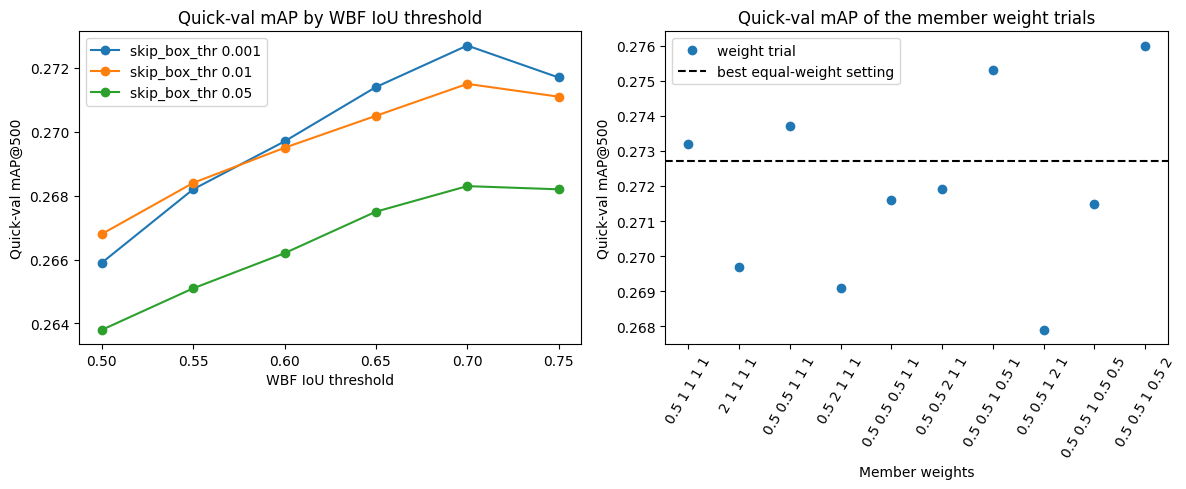

In [20]:
stage_one = history.filter(pl.col("stage") == 1)
stage_two = history.filter(pl.col("stage") == 2)
fig, (grid_ax, weight_ax) = plt.subplots(1, 2, figsize=FIGURE_SIZE)
for skip_box_threshold in WBF_SKIP_BOX_THRESHOLD_GRID:
    skip_rows = stage_one.filter(pl.col("skip_box_threshold") == skip_box_threshold)
    grid_ax.plot(
        skip_rows["iou_threshold"], skip_rows["val_mAP"], marker="o", label=f"skip_box_thr {skip_box_threshold:g}"
    )
grid_ax.set_title("Quick-val mAP by WBF IoU threshold")
grid_ax.set_xlabel("WBF IoU threshold")
grid_ax.set_ylabel("Quick-val mAP@500")
grid_ax.legend()
weight_ax.plot(range(stage_two.height), stage_two["val_mAP"], marker="o", linestyle="", label="weight trial")
weight_ax.axhline(stage_one["val_mAP"].max(), linestyle="--", color="black", label="best equal-weight setting")
weight_ax.set_xticks(range(stage_two.height), labels=stage_two["weights"].to_list())
weight_ax.tick_params(axis="x", labelrotation=60)
weight_ax.set_title("Quick-val mAP of the member weight trials")
weight_ax.set_xlabel("Member weights")
weight_ax.set_ylabel("Quick-val mAP@500")
weight_ax.legend()
save_figure(fig, "tuning_quick_val", history)

## Validation

The tuned fusion is applied to all val frames. Quick val is a subset of val and was used to tune the settings (and to select the members' checkpoints), so this score is slightly optimistic. Speed protocol: the sum of the members' recorded `ms_per_image` plus `perf_counter` around the WBF call per frame (CPU, one process, all val frames, member inference excluded).

In [21]:
fusion_started = time.perf_counter()
val_detections_by_key = fuse_frames(
    val_detections_by_member, val_keys, val_size_by_key, tuned_weights, tuned_iou_threshold, tuned_skip_box_threshold
)
fusion_ms_per_image = 1000 * (time.perf_counter() - fusion_started) / len(val_keys)
members_ms_per_image = sum(member_result["ms_per_image"] for member_result in member_results)
ms_per_image = members_ms_per_image + fusion_ms_per_image
val_predictions = to_coco_results(val_detections_by_key, val_image_id_by_key)
(OUTPUT_DIR / "val_predictions.json").write_text(json.dumps(val_predictions))
val_evaluator = evaluate_coco(val_ground_truth, val_predictions)
val_metrics = summarise_metrics(val_evaluator)
print(
    f"{len(val_predictions)} detections | mAP {val_metrics['mAP']:.4f} "
    f"| fusion {fusion_ms_per_image:.1f} ms/image | members {members_ms_per_image:.1f} ms/image"
)

1423000 detections | mAP 0.2747 | fusion 97.0 ms/image | members 957.1 ms/image


`result.json` writer: the core keys are checked before writing. Keys that do not apply to a fusion run (`imgsz`, `epochs_planned`, `epochs_run`, `best_epoch`, `batch`, `lr`) are `null`; `train_hours` is the wall-clock time of the tuning search, and the GPU hours behind the members are in `members_train_hours`.

In [22]:
REQUIRED_RESULT_KEYS = [
    "run",
    "notebook",
    "model",
    "family",
    "variant",
    "parent_run",
    "changed_params",
    "seed",
    "imgsz",
    "epochs_planned",
    "epochs_run",
    "best_epoch",
    "batch",
    "lr",
    "train_frames",
    "val_frames",
    "frame_step",
    "ignore_strategy",
    "mAP",
    "mAP_maxdet100",
    "AP50",
    "AP75",
    "AP_small",
    "AP_medium",
    "AP_large",
    "AR500",
    "ms_per_image",
    "speed_protocol",
    "train_hours",
    "gpu_name",
    "versions",
    "started_at",
    "finished_at",
]
FAMILIES = ["two_stage", "one_stage_anchor", "anchor_free", "query", "pipeline"]
VARIANTS = ["initial", "tuned"]


def write_result(result: dict[str, object]) -> None:
    missing_keys = [key for key in REQUIRED_RESULT_KEYS if key not in result]
    if missing_keys:
        raise ValueError(f"result.json is missing core keys: {missing_keys}")
    if result["family"] not in FAMILIES or result["variant"] not in VARIANTS:
        raise ValueError(f"Invalid family or variant: {result['family']}, {result['variant']}")
    (OUTPUT_DIR / "result.json").write_text(json.dumps(result, indent=2))

The run summary, shown as a one-row table (without the list and dict entries).

In [23]:
result: dict[str, object] = {
    "run": RUN_NAME,
    "notebook": f"new-notebooks/{RUN_NAME}.ipynb",
    "model": MODEL_NAME,
    "family": FAMILY,
    "variant": VARIANT,
    "parent_run": PARENT_RUN,
    "changed_params": CHANGED_PARAMS,
    "seed": SEED,
    "imgsz": None,
    "epochs_planned": None,
    "epochs_run": None,
    "best_epoch": None,
    "batch": None,
    "lr": None,
    "train_frames": train_frames.height,
    "val_frames": val_frames.height,
    "frame_step": FRAME_STEP,
    "ignore_strategy": IGNORE_STRATEGY,
    **val_metrics,
    "ms_per_image": round(ms_per_image, 1),
    "speed_protocol": SPEED_PROTOCOL,
    "train_hours": round(tuning_hours, 2),
    "gpu_name": gpu_name,
    "versions": package_versions,
    "started_at": started_at,
    "finished_at": datetime.now(UTC).isoformat(timespec="seconds"),
    "source_kernels": list(SOURCE_KERNELS),
    "member_labels": list(MEMBER_LABELS),
    "member_imgsz": [int(member_result["imgsz"]) for member_result in member_results],
    "members_ms_per_image": round(members_ms_per_image, 1),
    "fusion_ms_per_image": round(fusion_ms_per_image, 1),
    "members_train_hours": round(sum(member_result["train_hours"] for member_result in member_results), 2),
    "wbf_confidence_type": WBF_CONFIDENCE_TYPE,
    "wbf_iou_threshold": tuned_iou_threshold,
    "wbf_skip_box_threshold": tuned_skip_box_threshold,
    "wbf_member_weights": list(tuned_weights),
    "quick_val_mAP_tuned": best_quick_val_map,
}
write_result(result)
pl.DataFrame([{key: value for key, value in result.items() if not isinstance(value, list | dict)}])

run,notebook,model,family,variant,parent_run,seed,imgsz,epochs_planned,epochs_run,best_epoch,batch,lr,train_frames,val_frames,frame_step,ignore_strategy,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,speed_protocol,train_hours,gpu_name,started_at,finished_at,members_ms_per_image,fusion_ms_per_image,members_train_hours,wbf_confidence_type,wbf_iou_threshold,wbf_skip_box_threshold,quick_val_mAP_tuned
str,str,str,str,str,str,i64,null,null,null,null,null,null,i64,i64,i64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,f64,str,str,str,f64,f64,f64,str,f64,f64,f64
"""pipeline-ensemble-wbf""","""new-notebooks/pipeline-ensembl…","""class-wise WBF (ensemble-boxes…","""pipeline""","""tuned""","""faster-rcnn-small-anchors""",42,null,null,null,null,null,null,4868,2846,5,"""per_image_mean_fill""",0.2747,0.2737,0.5268,0.2517,0.1541,0.2506,0.4664,0.4842,1054.1,"""sum of the members' recorded m…",0.91,"""none (CPU)""","""2026-11-04T08:11:24+00:00""","""2026-11-04T10:13:15+00:00""",957.1,97.0,18.63,"""avg""",0.7,0.001,0.276


Per-class AP and AP50 on all val frames. How to read this table: one row per class, AP is AP@[.50:.95] at 500 detections per frame, empty when the class has no GT in val.

In [24]:
per_class_ap = build_per_class_ap(val_evaluator)
per_class_ap.write_csv(OUTPUT_DIR / "per_class_ap.csv")
per_class_ap

class_id,class_name,AP,AP50
i64,str,f64,f64
0,"""person""",0.3111,0.7166
1,"""bicycle""",0.2852,0.6107
2,"""car""",0.4396,0.69
3,"""van""",0.279,0.4995
4,"""truck""",0.3541,0.5809
5,"""tricycle""",0.2965,0.6108
6,"""bus""",0.082,0.1013
7,"""motor""",0.1499,0.4046


Per-clip AP of the fused detections (see the description above). How to read this table: one row per val clip; `AP` is AP@[.50:.95] at 500 detections per frame (the headline definition), `AP50` is AP at IoU 0.5, `AP_small` is AP on objects under 32² px, empty when the clip has no GT of that size. Written to `per_clip_ap.csv`.

In [25]:
per_clip_ap = build_per_clip_ap(val_predictions)
per_clip_ap.write_csv(OUTPUT_DIR / "per_clip_ap.csv")
per_clip_ap

clip,frames,AP,AP50,AP_small
str,i64,f64,f64,f64
"""uav0000086_00000_v""",464,0.309,0.6686,0.265
"""uav0000117_02622_v""",349,0.3138,0.5932,0.0356
"""uav0000137_00458_v""",233,0.361,0.7356,0.0131
"""uav0000182_00000_v""",363,0.2414,0.5228,0.182
"""uav0000268_05773_v""",978,0.1614,0.276,0.0015
"""uav0000305_00000_v""",184,0.316,0.4581,0.0597
"""uav0000339_00001_v""",275,0.3035,0.5417,0.1001


AP and recall by object size on all val frames, taken from the full-val evaluator. Buckets are COCO's, in original pixels: small < 32², medium < 96², large otherwise. How to read this table: `objects` counts the non-crowd val GT boxes in the bucket (the `all` row is the total, so rows overlap). `AP` and `AP50` are precision-based at 500 detections per frame. `AR500` is the recall averaged over IoU .50:.95 and `recall50` is the recall at IoU 0.5, both at 500 detections per frame. Written to `size_breakdown.csv`.

In [26]:
def read_eval_array(evaluator: COCOeval, name: str) -> np.ndarray:
    values = evaluator.eval[name]
    if not isinstance(values, np.ndarray):
        raise RuntimeError(f"COCOeval has no {name} array; call accumulate() first")
    return values


def build_size_breakdown(evaluator: COCOeval) -> pl.DataFrame:
    precision = read_eval_array(evaluator, "precision")
    recall = read_eval_array(evaluator, "recall")
    areas = np.concatenate(
        [(targets[:, 2] - targets[:, 0]) * (targets[:, 3] - targets[:, 1]) for targets in val_targets_by_key.values()]
    )
    object_counts = [
        len(areas),
        int((areas < SMALL_AREA).sum()),
        int(((areas >= SMALL_AREA) & (areas < MEDIUM_AREA)).sum()),
        int((areas >= MEDIUM_AREA).sum()),
    ]
    return pl.DataFrame(
        [
            {
                "size": size_name,
                "objects": object_count,
                "AP": average_valid_precision(precision[:, :, :, area_index, -1]),
                "AP50": average_valid_precision(precision[0, :, :, area_index, -1]),
                "AR500": average_valid_precision(recall[:, :, area_index, -1]),
                "recall50": average_valid_precision(recall[0, :, area_index, -1]),
            }
            for area_index, (size_name, object_count) in enumerate(
                zip(["all", "small", "medium", "large"], object_counts, strict=True)
            )
        ],
        schema={
            "size": pl.String,
            "objects": pl.Int64,
            "AP": pl.Float64,
            "AP50": pl.Float64,
            "AR500": pl.Float64,
            "recall50": pl.Float64,
        },
    )


size_breakdown = build_size_breakdown(val_evaluator)
size_breakdown.write_csv(OUTPUT_DIR / "size_breakdown.csv")
size_breakdown

size,objects,AP,AP50,AR500,recall50
str,i64,f64,f64,f64,f64
"""all""",114132,0.2747,0.5268,0.4842,0.8032
"""small""",21910,0.1541,0.4068,0.3182,0.7208
"""medium""",79357,0.2506,0.5104,0.4435,0.7738
"""large""",12865,0.4664,0.7377,0.6684,0.9475


## Ensemble ablation

The question: what does each member give alone, and what do subsets of members give when fused with the tuned IoU threshold and `skip_box_thr`? Rows: each member alone (its saved detections, no fusion); each pair of members; the four Faster R-CNN members; all five with equal weights; all five with the tuned weights (the final ensemble). In subset rows, each member keeps its tuned weight; the equal-weight row uses weight 1.0 for all. All rows are evaluated on all 2,846 val frames with the same COCOeval, and the 12 fused subsets run in the pool.

How to read this table: one row per configuration. `config` lists the members joined by `+`; `n_members` is their number. `mAP` is AP@[.50:.95] at 500 detections per frame, `AP_small` is AP on objects under 32² px, `AP_bus` is the AP of the bus class, and `AP_<clip>` is the AP on that clip alone. The tuned settings were chosen on quick-val frames only, so the rows that fuse members are slightly optimistic relative to the single-member rows. Written to `ensemble_ablation.csv`.

In [27]:
def evaluate_fused_subset(job: tuple[tuple[int, ...], tuple[float, ...], float, float]) -> dict[str, float]:
    member_indices, weights, iou_threshold, skip_box_threshold = job
    detections_by_key = fuse_frames(
        [val_detections_by_member[index] for index in member_indices],
        val_keys,
        val_size_by_key,
        weights,
        iou_threshold,
        skip_box_threshold,
    )
    return evaluate_detections(detections_by_key)


all_indices = tuple(range(len(MEMBER_LABELS)))
faster_rcnn_indices = tuple(index for index, label in enumerate(MEMBER_LABELS) if label in FASTER_RCNN_LABELS)
subset_specs: list[tuple[str, tuple[int, ...], tuple[float, ...]]] = [
    (f"{MEMBER_LABELS[first]}+{MEMBER_LABELS[second]}", (first, second), (tuned_weights[first], tuned_weights[second]))
    for first, second in combinations(all_indices, 2)
]
subset_specs.append(
    ("+".join(FASTER_RCNN_LABELS), faster_rcnn_indices, tuple(tuned_weights[i] for i in faster_rcnn_indices))
)
subset_specs.append(("+".join(MEMBER_LABELS) + " (equal weights)", all_indices, default_weights))
fused_rows = run_in_pool(
    evaluate_fused_subset,
    [(indices, weights, tuned_iou_threshold, tuned_skip_box_threshold) for _, indices, weights in subset_specs],
)
final_config_name = "+".join(MEMBER_LABELS) + " (tuned weights)"
final_row = build_metric_row(val_evaluator, per_clip_ap)
ablation = pl.DataFrame(
    [
        *[{"config": label, "n_members": 1, **row} for label, row in zip(MEMBER_LABELS, single_rows, strict=True)],
        *[
            {"config": name, "n_members": len(indices), **row}
            for (name, indices, _), row in zip(subset_specs, fused_rows, strict=True)
        ],
        {"config": final_config_name, "n_members": len(MEMBER_LABELS), **final_row},
    ]
)
ablation.write_csv(OUTPUT_DIR / "ensemble_ablation.csv")
ablation

job 1/12 | 15.1 min
job 2/12 | 13.2 min
job 3/12 | 12.7 min
job 4/12 | 16.0 min
job 5/12 | 14.8 min
job 6/12 | 14.9 min
job 7/12 | 16.6 min
job 8/12 | 13.0 min
job 9/12 | 16.3 min
job 10/12 | 16.0 min
job 11/12 | 17.2 min
job 12/12 | 19.0 min


config,n_members,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,AP_bus,AP_uav0000086_00000_v,AP_uav0000117_02622_v,AP_uav0000137_00458_v,AP_uav0000182_00000_v,AP_uav0000268_05773_v,AP_uav0000305_00000_v,AP_uav0000339_00001_v
str,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""T1""",1,0.2312,0.2311,0.4797,0.1957,0.1212,0.216,0.4127,0.4555,0.0311,0.2329,0.2767,0.3267,0.2024,0.117,0.2417,0.2891
"""T2""",1,0.229,0.2286,0.4789,0.1909,0.1194,0.2136,0.4196,0.4719,0.0449,0.2325,0.2774,0.3257,0.2109,0.1358,0.2925,0.2431
"""T3""",1,0.2371,0.237,0.4896,0.2016,0.1312,0.2185,0.4324,0.4802,0.0476,0.2751,0.2761,0.3326,0.2169,0.1407,0.2717,0.248
"""P3""",1,0.2247,0.2244,0.4613,0.1939,0.1163,0.2109,0.4005,0.4437,0.0318,0.146,0.2461,0.3237,0.201,0.1347,0.259,0.2715
"""T7""",1,0.2165,0.2154,0.4288,0.1894,0.1146,0.212,0.3415,0.3639,0.0802,0.2695,0.2448,0.3166,0.188,0.0663,0.251,0.2537
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""T3+T7""",2,0.2654,0.2643,0.5095,0.2423,0.144,0.2401,0.4513,0.468,0.115,0.3054,0.2966,0.3454,0.2302,0.1485,0.3172,0.2882
"""P3+T7""",2,0.2458,0.2447,0.4768,0.2219,0.1278,0.2312,0.4165,0.4143,0.074,0.2731,0.2715,0.3372,0.2144,0.1432,0.2841,0.2844
"""T1+T2+T3+P3""",4,0.2608,0.2601,0.5185,0.2329,0.1459,0.2405,0.4561,0.499,0.0467,0.2757,0.2989,0.3563,0.2364,0.1544,0.3057,0.2874


Ablation figure: full-val mAP@500 and AP_small for every configuration of the table above.

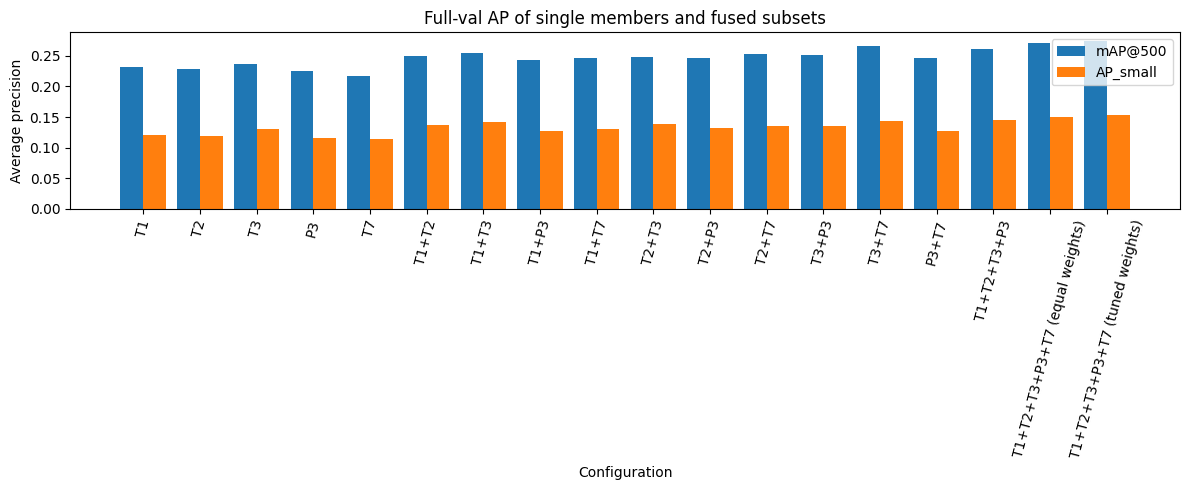

In [28]:
fig, ax = plt.subplots(figsize=FIGURE_SIZE)
positions = np.arange(ablation.height)
ax.bar(positions - 0.2, ablation["mAP"], width=0.4, label="mAP@500")
ax.bar(positions + 0.2, ablation["AP_small"], width=0.4, label="AP_small")
ax.set_xticks(positions, labels=ablation["config"].to_list())
ax.tick_params(axis="x", labelrotation=75)
ax.set_title("Full-val AP of single members and fused subsets")
ax.set_xlabel("Configuration")
ax.set_ylabel("Average precision")
ax.legend()
save_figure(fig, "ensemble_ablation", ablation.select("config", "n_members", "mAP", "AP_small"))

## Noise and clip-metric diagnostics

The question: how large are the differences between runs compared with the spread across the 7 val clips? The table has one row per run (the five members and the final ensemble), built from the per-clip AP columns of `ensemble_ablation.csv`; no new detections are evaluated.

How to read this table: `AP_<clip>` is the AP on that clip. `clip_mean` is the unweighted mean of the 7 clip APs; `clip_mean_without_4k` is the same mean over the 6 clips without the 4K clip `uav0000268_05773_v` (34 % of val frames; no test clip is that wide). For every run except the reference `T1`, `delta_clip_mean` is the mean over clips of (AP of the run − AP of T1). `loo_delta_min` and `loo_delta_max` are the smallest and largest value of this mean when one clip is left out at a time (leave-one-clip-out). `bootstrap_delta_low` and `bootstrap_delta_high` are the 2.5 % and 97.5 % percentiles of the mean delta when the 7 clips are resampled with replacement `BOOTSTRAP_RESAMPLES` times (seeded generator, the same resamples for every run; Efron 1979). `positive_clips` is the number of clips on which the run is above T1. With 7 clips the intervals are coarse. The delta columns are empty in the T1 row. Written to `val_noise.csv`.

In [29]:
def summarise_clip_noise(
    clip_aps: np.ndarray, reference_aps: np.ndarray, is_four_k: np.ndarray, bootstrap_indices: np.ndarray
) -> dict[str, float]:
    deltas = clip_aps - reference_aps
    leave_one_out_means = [float(np.delete(deltas, index).mean()) for index in range(len(deltas))]
    bootstrap_means = deltas[bootstrap_indices].mean(axis=1)
    low, high = np.percentile(bootstrap_means, BOOTSTRAP_INTERVAL)
    return {
        "delta_clip_mean": round(float(deltas.mean()), 4),
        "loo_delta_min": round(min(leave_one_out_means), 4),
        "loo_delta_max": round(max(leave_one_out_means), 4),
        "bootstrap_delta_low": round(float(low), 4),
        "bootstrap_delta_high": round(float(high), 4),
        "positive_clips": int((deltas > 0).sum()),
    }


NOISE_DELTA_FIELDS = [
    "delta_clip_mean",
    "loo_delta_min",
    "loo_delta_max",
    "bootstrap_delta_low",
    "bootstrap_delta_high",
    "positive_clips",
]
clip_columns = [f"AP_{clip}" for clip in val_clips]
noise_runs = ablation.filter(pl.col("config").is_in([*MEMBER_LABELS, final_config_name]))
is_four_k = np.array([clip == FOUR_K_CLIP for clip in val_clips])
reference_aps = noise_runs.filter(pl.col("config") == REFERENCE_MEMBER_LABEL).select(clip_columns).to_numpy()[0]
bootstrap_indices = np.random.default_rng(SEED).integers(0, len(val_clips), size=(BOOTSTRAP_RESAMPLES, len(val_clips)))
noise_rows = []
for config, *clip_values in noise_runs.select("config", *clip_columns).iter_rows():
    clip_aps = np.array(clip_values)
    delta_fields = (
        summarise_clip_noise(clip_aps, reference_aps, is_four_k, bootstrap_indices)
        if config != REFERENCE_MEMBER_LABEL
        else dict.fromkeys(NOISE_DELTA_FIELDS, None)
    )
    noise_rows.append(
        {
            "run": config,
            **dict(zip(clip_columns, clip_values, strict=True)),
            "clip_mean": round(float(clip_aps.mean()), 4),
            "clip_mean_without_4k": round(float(clip_aps[~is_four_k].mean()), 4),
            **delta_fields,
        }
    )
val_noise = pl.DataFrame(noise_rows, infer_schema_length=None)
val_noise.write_csv(OUTPUT_DIR / "val_noise.csv")
val_noise

run,AP_uav0000086_00000_v,AP_uav0000117_02622_v,AP_uav0000137_00458_v,AP_uav0000182_00000_v,AP_uav0000268_05773_v,AP_uav0000305_00000_v,AP_uav0000339_00001_v,clip_mean,clip_mean_without_4k,delta_clip_mean,loo_delta_min,loo_delta_max,bootstrap_delta_low,bootstrap_delta_high,positive_clips
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,i64
"""T1""",0.2329,0.2767,0.3267,0.2024,0.117,0.2417,0.2891,0.2409,0.2616,null,null,null,null,null,null
"""T2""",0.2325,0.2774,0.3257,0.2109,0.1358,0.2925,0.2431,0.2454,0.2637,0.0045,-0.0032,0.0129,-0.0148,0.0244,4
"""T3""",0.2751,0.2761,0.3326,0.2169,0.1407,0.2717,0.248,0.2516,0.2701,0.0107,0.0054,0.0193,-0.0102,0.0282,5
"""P3""",0.146,0.2461,0.3237,0.201,0.1347,0.259,0.2715,0.226,0.2412,-0.0149,-0.0204,-0.0029,-0.0427,0.0067,2
"""T7""",0.2695,0.2448,0.3166,0.188,0.0663,0.251,0.2537,0.2271,0.2539,-0.0138,-0.0222,-0.0077,-0.0324,0.0085,2
"""T1+T2+T3+P3+T7 (tuned weights)""",0.309,0.3138,0.361,0.2414,0.1614,0.316,0.3035,0.2866,0.3075,0.0457,0.0406,0.0509,0.0308,0.0615,7


## Bus diagnostic

The question: is the low AP of the bus class limited by recall, or by the class of the detections that cover the bus boxes? For every non-crowd bus GT box of the val frames (`BUS_CLASS`), the detections of the run (up to 500 per frame, score at least 0.001) are compared with the box by IoU, and the threshold is `BUS_IOU_THRESHOLD`. The boxes of the five members and of the final ensemble are analysed with the same code.

How to read this table: one row per run. `bus_gt` is the number of bus GT boxes. `recall50_any_class` is the share of them with at least one detection of any class at IoU ≥ 0.5; `recall50_bus_class` is the share with at least one detection of the class bus at IoU ≥ 0.5. `matched_boxes` is the number of bus GT boxes covered by at least one detection of any class. For these boxes, `top_<class>` is the share whose top-scoring covering detection (IoU ≥ 0.5) has that class, so the eight shares add to 1. `AP_bus` is the AP of the bus class from `ensemble_ablation.csv`. Written to `bus_diagnostic.csv`.

In [30]:
def summarise_bus_matches(detections_by_key: dict[str, FrameDetections]) -> dict[str, float]:
    bus_class_id = CLASSES.index(BUS_CLASS)
    top_class_counts = dict.fromkeys(CLASSES, 0)
    gt_count = 0
    covered_count = 0
    correct_class_count = 0
    for key, targets in val_targets_by_key.items():
        gt_boxes = np.ascontiguousarray(targets[targets[:, 4] == bus_class_id][:, :4])
        gt_count += len(gt_boxes)
        boxes, scores, class_ids = detections_by_key[key]
        if len(gt_boxes) == 0 or len(boxes) == 0:
            continue
        ious = box_iou(torch.from_numpy(gt_boxes), torch.from_numpy(boxes.astype(np.float32))).numpy()
        is_covering = ious >= BUS_IOU_THRESHOLD
        is_covered = is_covering.any(axis=1)
        covered_count += int(is_covered.sum())
        correct_class_count += int((is_covering & (class_ids == bus_class_id)[None, :]).any(axis=1).sum())
        for covering in is_covering[is_covered]:
            top_index = np.flatnonzero(covering)[np.argmax(scores[covering])]
            top_class_counts[CLASSES[int(class_ids[top_index])]] += 1
    return {
        "bus_gt": gt_count,
        "recall50_any_class": round(covered_count / gt_count, 4),
        "recall50_bus_class": round(correct_class_count / gt_count, 4),
        "matched_boxes": covered_count,
        **{f"top_{name}": round(count / max(covered_count, 1), 4) for name, count in top_class_counts.items()},
    }


bus_runs = [
    *zip(MEMBER_LABELS, val_detections_by_member, strict=True),
    (final_config_name, val_detections_by_key),
]
bus_diagnostic = pl.DataFrame(
    [
        {
            "run": name,
            **summarise_bus_matches(detections_by_key),
            "AP_bus": ablation.filter(pl.col("config") == name)["AP_bus"].item(),
        }
        for name, detections_by_key in bus_runs
    ]
)
bus_diagnostic.write_csv(OUTPUT_DIR / "bus_diagnostic.csv")
bus_diagnostic

run,bus_gt,recall50_any_class,recall50_bus_class,matched_boxes,top_person,top_bicycle,top_car,top_van,top_truck,top_tricycle,top_bus,top_motor,AP_bus
str,i64,f64,f64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""T1""",264,1.0,0.9356,264,0.0,0.0,0.7121,0.0152,0.1856,0.0038,0.0833,0.0,0.0311
"""T2""",264,1.0,0.947,264,0.0,0.0,0.6212,0.0341,0.125,0.0227,0.197,0.0,0.0449
"""T3""",264,1.0,0.9811,264,0.0,0.0,0.6818,0.0114,0.1894,0.0152,0.1023,0.0,0.0476
"""P3""",264,1.0,0.928,264,0.0,0.0,0.6477,0.1098,0.2348,0.0,0.0076,0.0,0.0318
"""T7""",264,0.9962,0.2045,263,0.0,0.0,0.6312,0.0342,0.2395,0.038,0.057,0.0,0.0802
"""T1+T2+T3+P3+T7 (tuned weights)""",264,0.9962,0.6932,263,0.0,0.0,0.6958,0.0152,0.2319,0.0076,0.0494,0.0,0.082


## Submission

Fuse the members' test detections (their `submission.csv` files) with the tuned settings and write `submission.csv`: one row per `test_images.csv` row in that order, 0-based class ids, top-left `x y w h` in original pixels, top 500 by score, empty string for frames without detections.

In [31]:
def format_prediction_string(boxes: np.ndarray, scores: np.ndarray, class_ids: np.ndarray) -> str:
    top_indices = np.argsort(-scores, kind="stable")[:MAX_DETECTIONS]
    groups = []
    for (x1, y1, x2, y2), score, class_id in zip(
        boxes[top_indices].tolist(), scores[top_indices].tolist(), class_ids[top_indices].tolist(), strict=True
    ):
        width = round(x2 - x1, 2)
        height = round(y2 - y1, 2)
        if width > 0 and height > 0:
            groups.append(f"{int(class_id)} {score:.4f} {x1:.2f} {y1:.2f} {width:.2f} {height:.2f}")
    return " ".join(groups)


test_detections_by_key = fuse_frames(
    test_detections_by_member,
    test_keys,
    test_size_by_key,
    tuned_weights,
    tuned_iou_threshold,
    tuned_skip_box_threshold,
)
prediction_by_image_id = {
    image_id: format_prediction_string(*test_detections_by_key[key])
    for image_id, key in test_images.select("image_id", "frame_key").iter_rows()
}
submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(prediction_by_image_id, default="", return_dtype=pl.String)
)
submission.write_csv(OUTPUT_DIR / "submission.csv")
print(f"submission.csv: {submission.height} rows, {(submission['PredictionString'] == '').sum()} empty")

submission.csv: 3811 rows, 0 empty


Format checks on the file as written to disk, against `test_images.csv` and the fixed columns `image_id,PredictionString` (the competition data has no `sample_submission.csv`). The results go to `submission_check.json`, and the notebook raises if any check fails.

In [32]:
SUBMISSION_COLUMNS = ["image_id", "PredictionString"]
SUBMISSION_FIELDS = ["class_id", "score", "x", "y", "w", "h"]


def check_submission(submission: pl.DataFrame, test_images: pl.DataFrame) -> dict[str, bool]:
    groups = (
        submission.join(test_images.select("image_id", "width", "height"), on="image_id", how="left")
        .filter(pl.col("PredictionString") != "")
        .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
    )
    boxes = groups.select(
        "width",
        "height",
        *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(SUBMISSION_FIELDS)],
    ).explode(SUBMISSION_FIELDS)
    return {
        "columns_match_submission_format": submission.columns == SUBMISSION_COLUMNS,
        "image_ids_match_test_images_order": submission["image_id"].equals(test_images["image_id"]),
        "image_ids_unique": bool(submission["image_id"].is_unique().all()),
        "values_multiple_of_six": bool(groups.select((pl.col("values").list.len() % 6 == 0).all()).item()),
        "at_most_max_detections_per_image": bool(
            groups.select((pl.col("values").list.len() <= 6 * MAX_DETECTIONS).all()).item()
        ),
        "class_ids_are_valid_integers": bool(
            boxes.select(
                (
                    pl.col("class_id").is_between(0, len(CLASSES) - 1)
                    & (pl.col("class_id") == pl.col("class_id").floor())
                ).all()
            ).item()
        ),
        "scores_in_unit_interval": bool(boxes["score"].is_between(0, 1).all()),
        "sizes_positive": bool(boxes.select(((pl.col("w") > 0) & (pl.col("h") > 0)).all()).item()),
        "boxes_inside_image": bool(
            boxes.select(
                (
                    (pl.col("x") >= -1)
                    & (pl.col("y") >= -1)
                    & (pl.col("x") + pl.col("w") <= pl.col("width") + 1)
                    & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)
                ).all()
            ).item()
        ),
    }


submission_on_disk = pl.read_csv(
    OUTPUT_DIR / "submission.csv", schema={"image_id": pl.String, "PredictionString": pl.String}
).with_columns(pl.col("PredictionString").fill_null(""))
submission_check = check_submission(submission_on_disk, test_images)
(OUTPUT_DIR / "submission_check.json").write_text(json.dumps(submission_check, indent=2))
failed_checks = [name for name, is_passed in submission_check.items() if not is_passed]
if failed_checks:
    raise ValueError(f"Submission checks failed: {failed_checks}")
submission_check

{'columns_match_submission_format': True,
 'image_ids_match_test_images_order': True,
 'image_ids_unique': True,
 'values_multiple_of_six': True,
 'at_most_max_detections_per_image': True,
 'class_ids_are_valid_integers': True,
 'scores_in_unit_interval': True,
 'sizes_positive': True,
 'boxes_inside_image': True}

## References

- Solovyev, Wang, Gabruseva. Weighted boxes fusion: ensembling boxes from different object detection models. arXiv:1910.13302 (WBF, class-wise fusion, confidence rescaling).
- `ensemble-boxes` 1.0.10 (`weighted_boxes_fusion`), MIT licence: https://github.com/ZFTurbo/Weighted-Boxes-Fusion
- Ren, He, Girshick, Sun. Faster R-CNN: Towards Real-Time Object Detection with Region Proposal Networks. arXiv:1506.01497 (four of the five members).
- Ultralytics YOLO11 (member T7, trained in `dmnk1304/yolo11s-1280-p2`; not imported here), AGPL-3.0: https://github.com/ultralytics/ultralytics
- Lin et al. Microsoft COCO: Common Objects in Context (metric definitions). arXiv:1405.0312.
- Zhu et al. Detection and Tracking Meet Drones Challenge (VisDrone, ignored regions). arXiv:2001.06303.
- Efron. Bootstrap methods: another look at the jackknife. Annals of Statistics 7(1), 1979, https://doi.org/10.1214/aos/1176344552 (bootstrap and leave-one-out resampling of clips in `val_noise.csv`).
- pycocotools (COCOeval), BSD-2-Clause: https://github.com/cocodataset/cocoapi
- torchvision `ops.box_iou`, BSD-3-Clause: https://github.com/pytorch/vision/blob/main/torchvision/ops/boxes.py
- Python `concurrent.futures.ProcessPoolExecutor` and `multiprocessing` start methods: https://docs.python.org/3/library/concurrent.futures.html
- Source runs (kernel sources): T1 `faster-rcnn-small-anchors` (`new-notebooks/faster-rcnn-small-anchors.ipynb`), T2 `faster-rcnn-rpn-proposals`, T3 `faster-rcnn-giou`, P3 `pipeline-class-balance` (`new-notebooks/pipeline-class-balance.ipynb`), T7 `yolo11s-1280-p2`; their reports are in `experiments/` and `EXPERIMENTS.md`.
- Protocol code (split, COCO evaluation, per-clip AP, size breakdown, `result.json`, submission and checks): copied from `new-notebooks/pipeline-class-balance.ipynb`; no legacy notebook code is used.
- EDA notebook `notebooks/eda.ipynb` and its summary `EDA.md` (§5: the 4K val clip and the test resolutions).
- Planning document `SCOPE.md` (§3 principles, §3.10 decision rule, findings F10, F21, F35, F44, F49, F51, F53) as the source of the motivation numbers in the Overview.